In [9]:
import matplotlib.pyplot as plt
import pandas as pandas
import numpy as np

In [26]:
df = pd.DataFrame({
    'Height': [150, 168, 160, 175, 155, 182, 170, 162, 178, 165,
               185, 172, 158, 180, 167, 173, 163, 177, 169, 176],

    'Weight': [52, 59, 48, 70, 45, 76, 65, 57, 68, 54,
               80, 62, 50, 73, 61, 66, 55, 72, 60, 69]
})

Text(0, 0.5, 'Height')

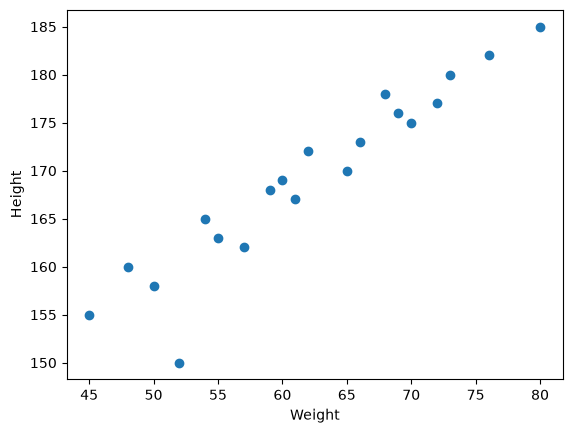

In [27]:
## scatter plot
plt.scatter(df['Weight'], df['Height'])
plt.xlabel("Weight")
plt.ylabel("Height")

In [28]:
## correlation

df.corr()

,Height,Weight
Height,1.000000,0.948511
Weight,0.948511,1.000000


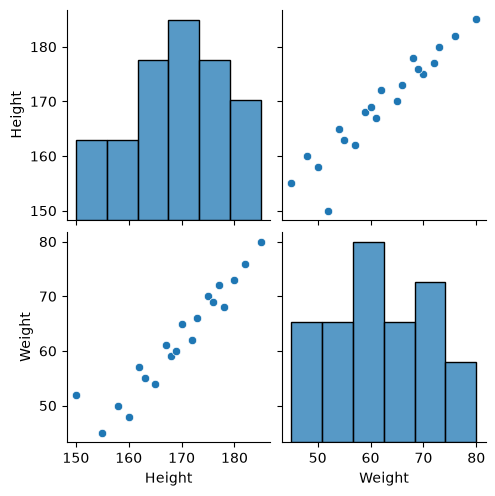

In [29]:
# Seaborn for visualization
import seaborn as sns
sns.pairplot(df)

In [80]:
## Independent and dependent features
df.head()
x=df[['Weight']] ## independent feature should be dataframe or 2d array
y = df['Height'] ## this variable can be in series or 1d array

In [81]:
## Train, Test Split
from sklearn.model_selection import train_test_split

In [82]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

In [83]:
## standardization
from sklearn.preprocessing import StandardScaler

In [84]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_train

array([[ 1.41766802],
       [ 0.03296902],
       [ 0.82422559],
       [-0.16484512],
       [-0.65938047],
       [ 1.1209468 ],
       [-1.35172997],
       [-0.75828754],
       [ 0.72531852],
       [-1.64845118],
       [-1.15391583],
       [-0.46156633],
       [ 1.8132963 ],
       [-0.06593805],
       [ 0.32969024]])

In [85]:
X_test = scaler.transform(X_test)
X_test

array([[-0.95610169],
       [ 1.02203973],
       [ 0.42859731],
       [-0.26375219],
       [ 0.62641145]])

In [86]:
## Apply Simple Linear Regression
from sklearn.linear_model import LinearRegression

In [87]:
regression = LinearRegression()

In [88]:
regression.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[8.57]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,169.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.87]


In [92]:
print("Coefficient or slope: ", regression.coef_)
print("Intercept: ", regression.intercept_)

Coefficient or slope:  [8.56755028]
Intercept:  169.26666666666668


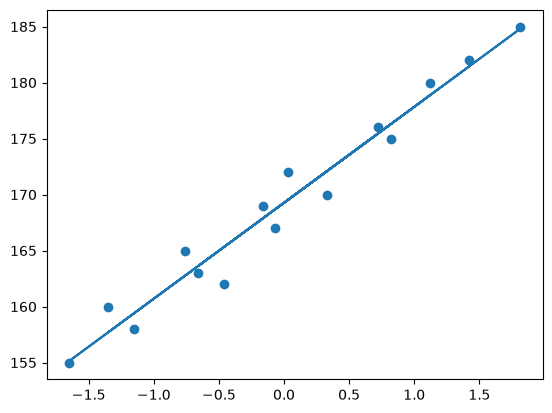

In [96]:
## plot Training data plot best fit line
plt.scatter(X_train, y_train)
plt.plot(X_train, regression.predict(X_train))

In [97]:
## Prediction for test data
y_pred = regression.predict(X_test)

In [98]:
## Performance Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [99]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

27.206084083175835
3.3038260869565192
5.215945176396684


In [100]:
from sklearn.metrics import r2_score

In [102]:
score = r2_score(y_test, y_pred)
print(score)

0.7398040925480506


In [103]:
## Display adjusted R-squared
1-(1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.6530721233974008

In [107]:
## OLS Linear Regression
import statsmodels.api as sm

In [108]:
model = sm.OLS(y_train, X_train).fit()

In [110]:
prediction = model.predict(X_test)
print(prediction)

[-8.19144928  8.75637681  3.67202899 -2.25971014  5.36681159]


In [112]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                 Height   R-squared (uncentered):                   0.003
Model:                            OLS   Adj. R-squared (uncentered):             -0.069
Method:                 Least Squares   F-statistic:                            0.03586
Date:                Mon, 16 Nov 2026   Prob (F-statistic):                       0.853
Time:                        17:34:06   Log-Likelihood:                         -98.257
No. Observations:                  15   AIC:                                      198.5
Df Residuals:                      14   BIC:                                      199.2
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [116]:
## Prediction for new data
regression.predict(scaler.transform([[72]]))

e:\Work\Learning\Machine Learning\ML - NLP - MLOP\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([178.02304348])